### Packages

In [12]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
import matplotlib.pyplot as plt
import sklearn.datasets as datasets
import pandas as pd
import numpy as np
from scipy.stats import norm,beta,chi2
import seaborn as sns
sns.set_style("whitegrid")

import torch
from torch import nn
from torch import optim
from torch.nn import functional as F

### Functions

In [14]:
from ldf import ldf
from pit import pit
from pit import plot_pit_histograms

from rational_quadratic import rational_quadratic_spline
from pit import nsf_pit, split_equal, test_and_interpret_pit, crps, nsf_pit_crps
from time_varying_nsf import tvnsf_pit,compute_ece, tvnsf_pit_crps, nsf_pit_estimation
from utils.utils import tlp,geom_3f2
from beta_transform import online_beta_calibration, plot_parameter_evolution

### DGP

In [15]:
### Fix the seed for reproducibility
np.random.seed(0)

### Define DGP constants
phi = 0.9
sigma_x = 0.3 # 1# 
sigma_y = 0.3 # 0.5 # 
sigma_z = 0.1 # 1# 
K = 20  # number of forecasters
T = 2001  ## number of time steps

# Define levels of the process
levels = np.asarray([0]*50 + [-1]*50 + [1]*50 + [-1]*50 + [0]*200 + [-1]*400 + [0]*50 + [-1]*50 + [1]*50 + [-1]*10 + [1]*10 + [0]*10 + [-1]*10 + [1]*10  + [0]*50 + [1]*50 + [0]*50 + [-1]*50 + [1]*400 + [0]*50 + [-1]*50 + [1]*50 + [0]*50 + [0]*201)

#levels = np.asarray([0]*100 + [-1]*100 + [1]*100 + [-1]*100 + [0]*400 + [-1]*800 + [0]*100 + [-1]*100 + [1]*100 + [-1]*20 + [1]*20 + [0]*20 + [-1]*20 + [1]*20  + [0]*100 + [1]*100 + [0]*100 + [-1]*100 + [1]*800 + [0]*100 + [-1]*100 + [1]*100 + [0]*100 + [0]*401)

def generate_dgp(levels):
    v_t = norm.rvs(size=T)
    e_t = norm.rvs(size=T)
    x = np.asarray([sigma_x * v_t[0]])
    for i in range(T-1):
        x = np.append(x, phi * x[-1] + sigma_x * v_t[i+1])
    y = phi * x + e_t * sigma_y
    y = y + levels[:T]
    return x, y


def get_forecasts(levels):
    x, y = generate_dgp(levels)
    z = x + norm.rvs(size=(K,T)) * sigma_z
    p = z # phi * z
    p = (p.T + np.linspace(-2,2,K)).T
    forecasts = pd.DataFrame(p)
    return forecasts, y

forecasts, sim_y = get_forecasts(levels)

In [16]:
forecasts_lik = pd.DataFrame(norm.pdf(sim_y, loc=forecasts.to_numpy(), scale=sigma_y))

# forecasters's cdfs
forecasts_cdf    = pd.DataFrame(norm.cdf(sim_y, loc=forecasts.to_numpy(), scale=sigma_y))  

# log likelihoods
log_likelihoods = np.log(forecasts_lik).astype(float).to_numpy() 

### LDF hyperparameters

In [17]:
discount_factors = np.array([1, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.001])
c = 10**-20 

### 2-level LDF(softmax, softmax)

In [18]:
%%time
res_ldf_2 = ldf(log_likelihoods, levels=2, discount_factors=[discount_factors, discount_factors], activation_functions=["softmax", "softmax"], c=c)
res_ldf_2_df = pd.DataFrame({'discount factors': discount_factors, 'log likelihood': res_ldf_2["logscores"].mean(axis=1)})
res_ldf_2_df

CPU times: total: 1.61 s
Wall time: 1.64 s


,discount factors,log likelihood
0,1.000,-0.471795
1,0.990,-0.437265
2,0.950,-0.405797
3,0.900,-0.398013
4,0.800,-0.395621
5,0.700,-0.397694
6,0.600,-0.400453
7,0.500,-0.403269
8,0.400,-0.406206
9,0.300,-0.409135


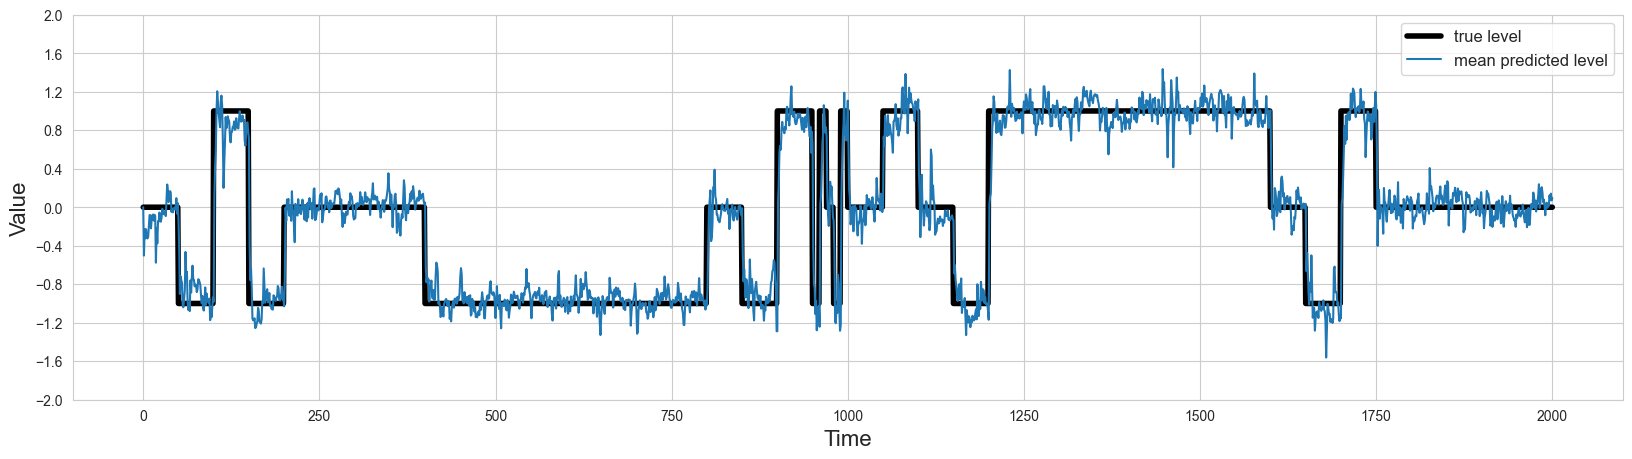

In [19]:
mean_pred_level = (np.linspace(-2,2,20) * res_ldf_2["weights"][5]).sum(axis=1)
sns.color_palette("tab10")
fig, ax = plt.subplots(1, 1, figsize=(20,5))
lns1 = ax.plot(range(len(levels)), levels, lw=4, label="true level", color="black")
lns2 = ax.plot(range(len(levels)), mean_pred_level , label="mean predicted level", color="tab:blue")
#lns3 = ax.plot(range(20, len(levels)), y[20:] , lw=0.5,label="y", color="red")
lns = lns1+lns2#+lns3
labs = [l.get_label() for l in lns]
ax.set_ylim(-2, 2)
ax.set_yticks(np.arange(-2, 2.4, 0.4))
ax.set_xlabel("Time", fontsize=16)
ax.set_ylabel("Value", fontsize=16)
ax.legend(lns, labs, loc='upper right', fontsize=12)

### x-grid

In [20]:
f = forecasts.values
mu_min, mu_max = f.min(), f.max()  # observed forecast means
margin = 3*sigma_y
x_min = mu_min - margin
x_max = mu_max + margin
M     = 1001  # odd so there’s a grid‐point exactly at the median
x_grid = np.linspace(x_min, x_max, M)

### TLP function (2D -> 3D raw cdf)

### Raw Forecasts CDF over x_grid

In [21]:
linear_pool = tlp(forecasts,x_grid, res_ldf_2['weights'],sigma_y)

### PIT values

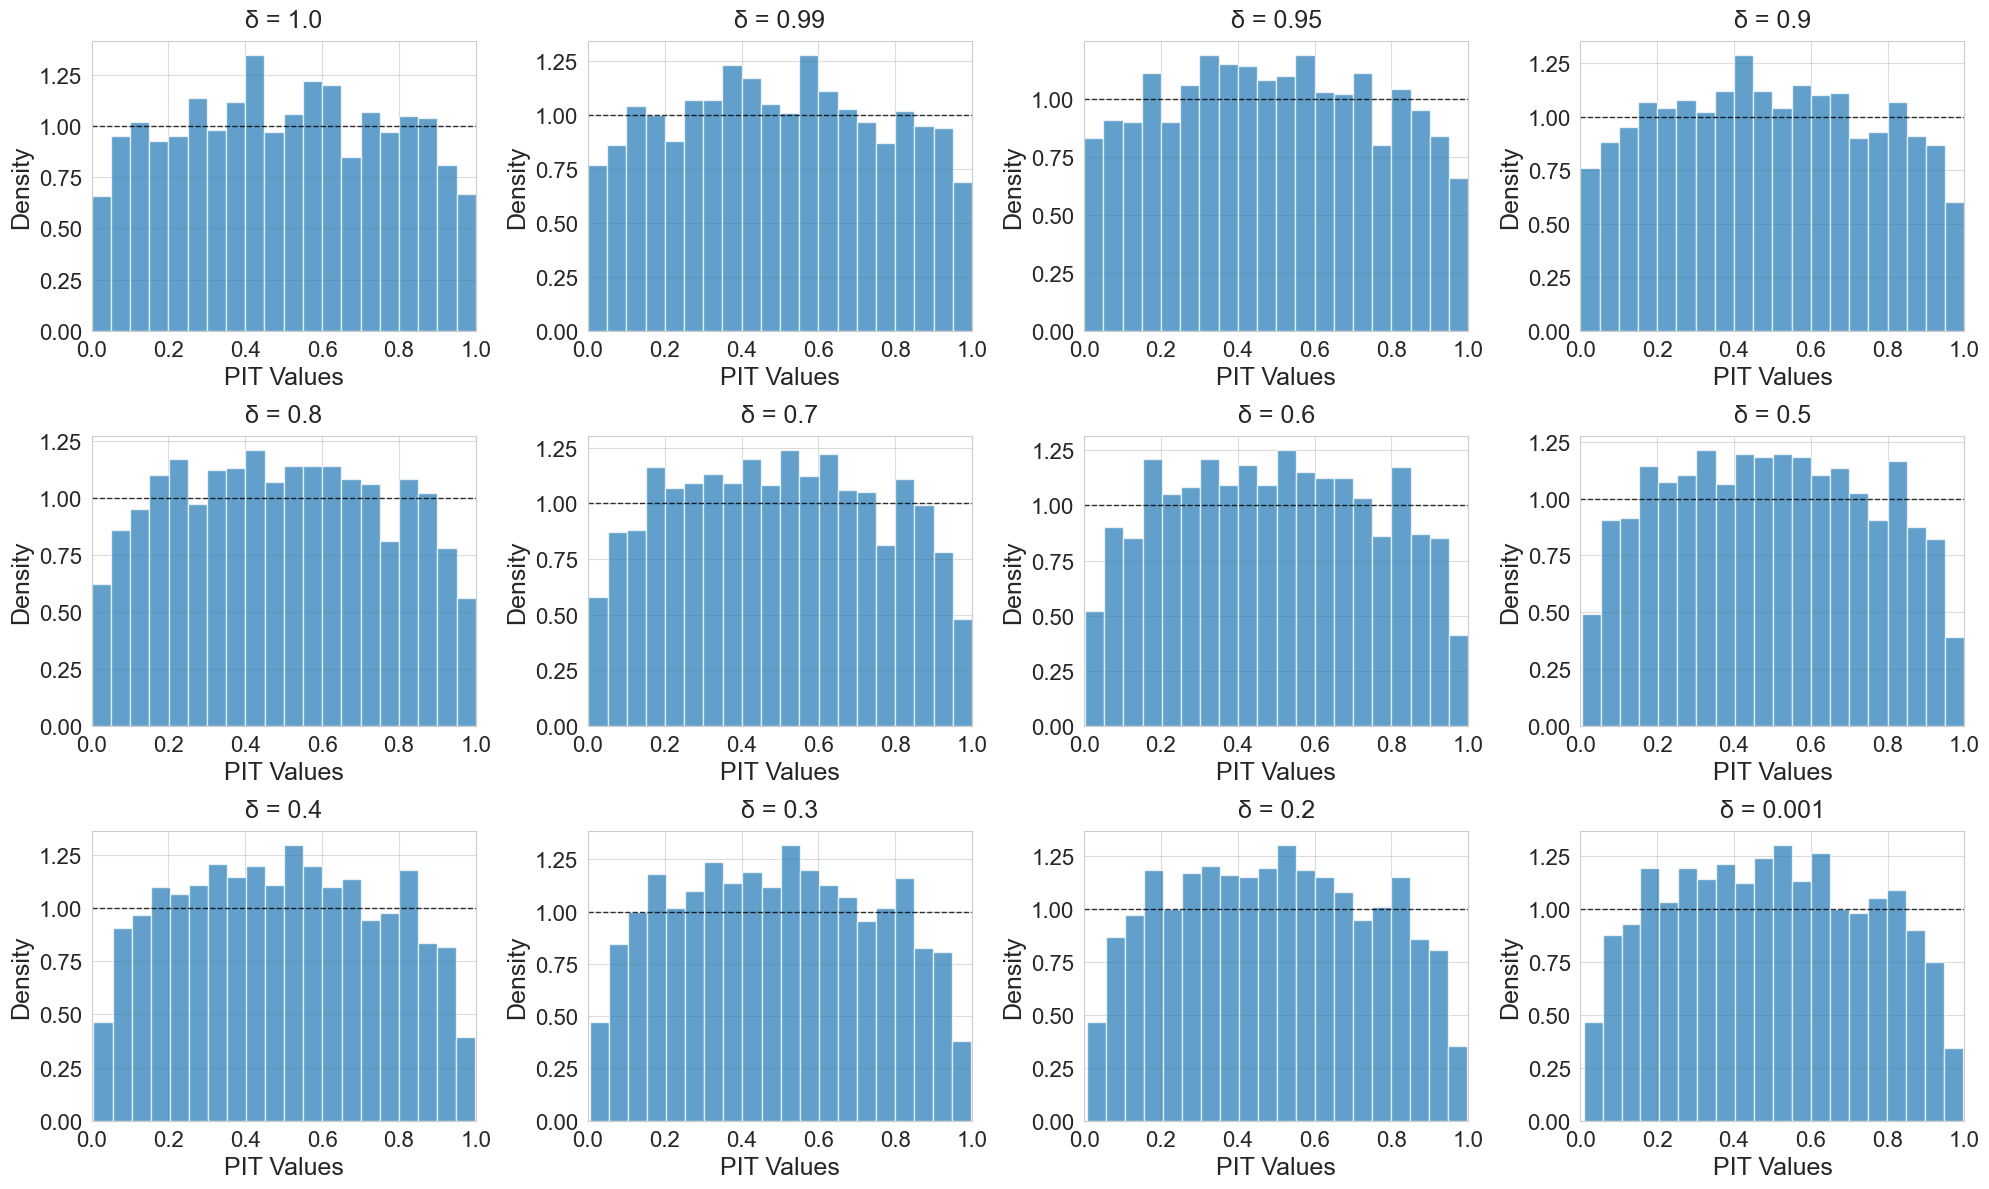

In [22]:
Raw_pit = pit(linear_pool, x_grid, sim_y)

plot_pit_histograms(Raw_pit, model_names = discount_factors)

### Beta Transform

In [23]:
tlp_param = {
    'forecast': forecasts,
    'x': x_grid,
    'weights': res_ldf_2['weights'],
    'sigma_y': sigma_y
    }

beta_transformed_pit = online_beta_calibration(
    x=x_grid,
    y_observations=sim_y,
    pool_func=tlp,
    pool_param=tlp_param,
    geom_3f2=geom_3f2,
    # Core BFGS/Newton parameters
    a0=1.0,
    b0=1.0,
    gamma=0.05,
    eta0=1.2,
    tau=50,
    alpha=0.55,

    # Basic calibration parameters
    outer_loop_freq=70,              # Correction frequency (t_freq in algorithm)
    min_samples=40,                  # Minimum samples for corrections (n_min in algorithm)
    
    # Algorithm 2: Shape detection parameters
    significance_level=0.15,          # α - significance level for chi-square tests
    k_bins_for_detection=10,          # k - number of bins for shape detection 
    
    # Algorithm 3: Shape-specific correction parameters
    correction_strength=0.4,        # λ - blend parameter for corrections
    param_floor=0.25,               # Lower bound for α,β parameters
    param_ceiling=5.00,             # Upper bound for α,β parameters
    
    # Window management
    rolling_window_size=75,        # w - rolling window size for corrections
    x_constant=1.2,
    # Numerical stability
    eps=1e-5)

Starting Online Beta Calibration
  Models (P): 12
  Time steps (T): 2001
  Grid points (M): 1001
  Initial parameters: α₀=1.0, β₀=1.0
  Learning rate: η₀=1.2, τ=50, α=0.55
  Correction strength: 0.4
------------------------------------------------------------
Step    0: α=0.9929, β=1.0056
Step  200: α=1.1322, β=1.0779
Step  400: α=1.6835, β=1.7371
Step  600: α=1.5780, β=1.6517
Step  800: α=1.2797, β=1.3428
Step 1000: α=1.2583, β=1.3174
Step 1200: α=1.2601, β=1.3188
Step 1400: α=1.1621, β=1.2041
Step 1600: α=1.1697, β=1.2060
Step 1800: α=1.1377, β=1.1737
Step 2000: α=1.1767, β=1.2118
------------------------------------------------------------
Online Beta Calibration Complete


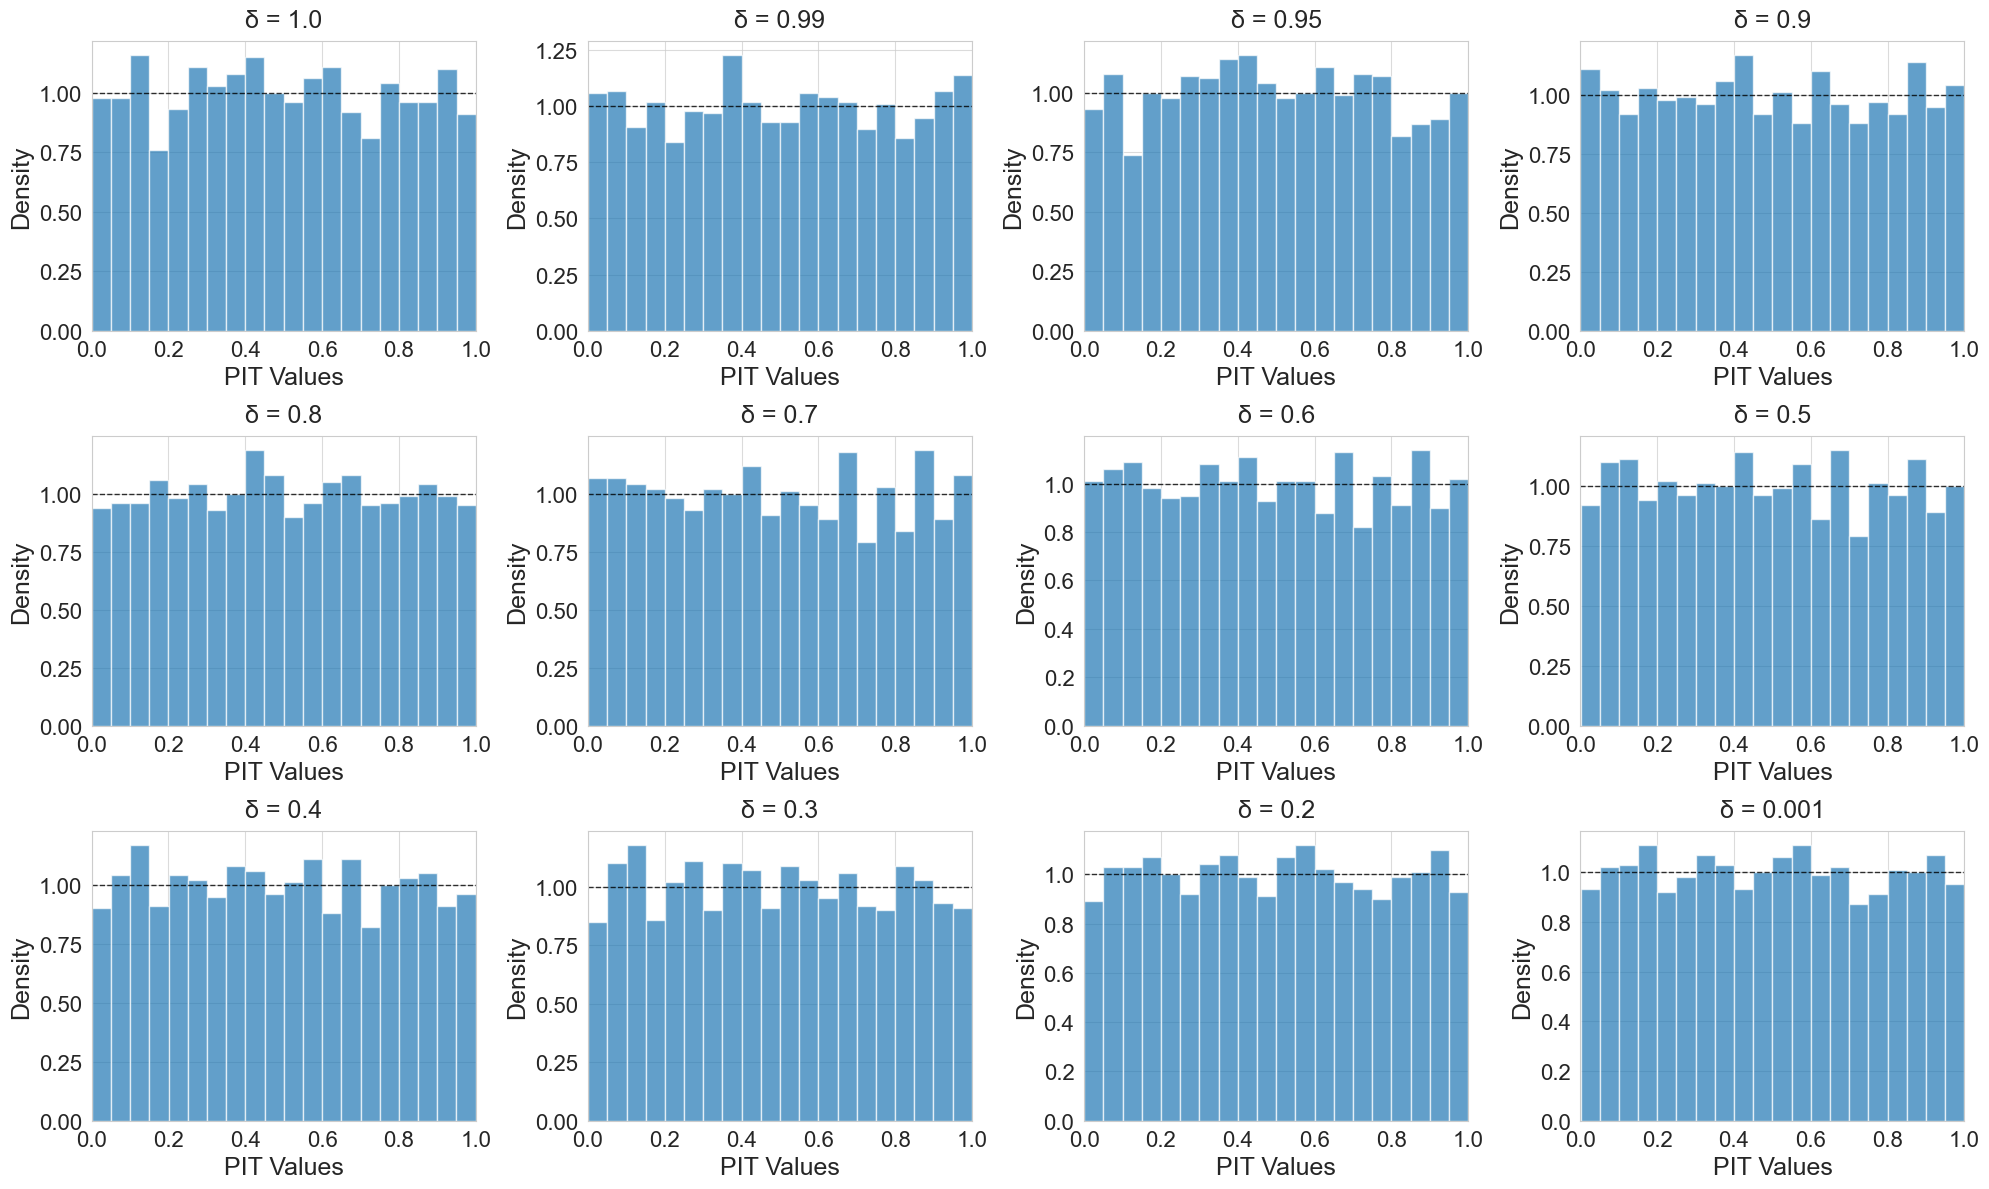

In [24]:
plot_pit_histograms(beta_transformed_pit['all_calibrated_cdfs'], model_names = discount_factors)

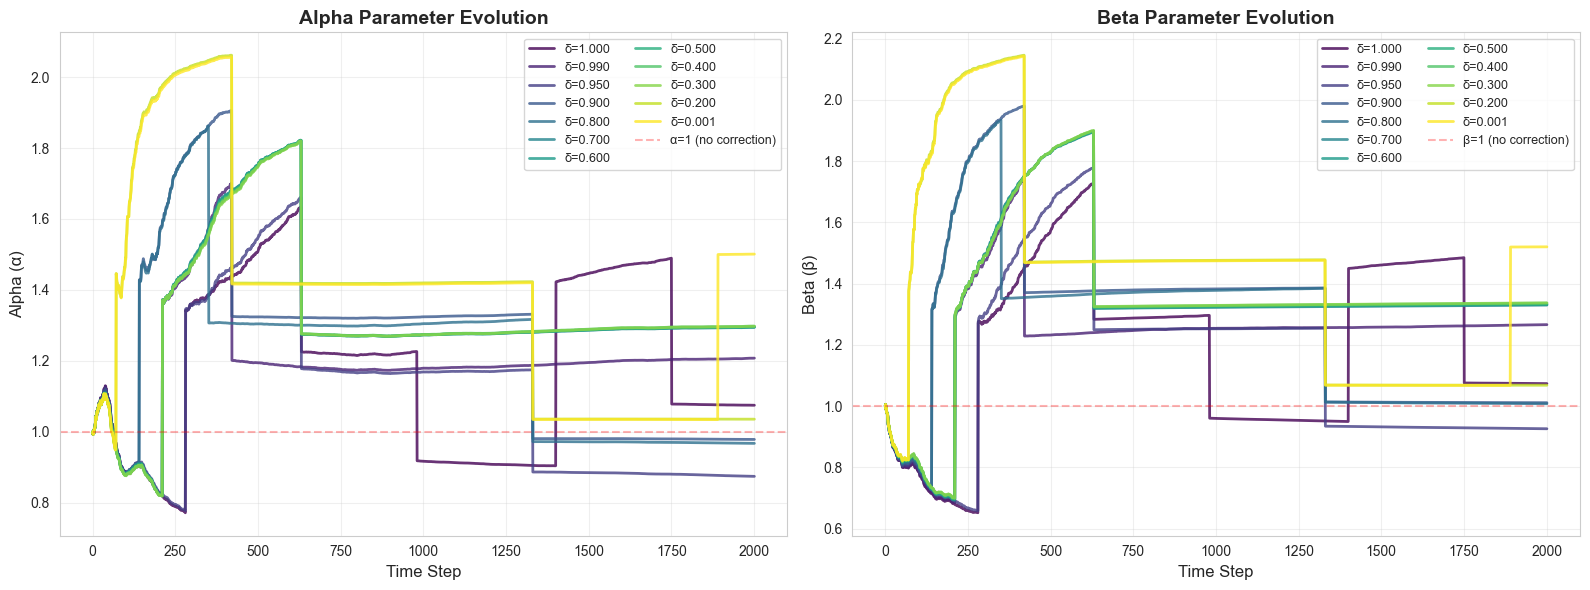

In [25]:
plot_parameter_evolution(beta_transformed_pit, discount_factors)

In [26]:
_, beta_tran_df = test_and_interpret_pit(
    pit_values=beta_transformed_pit['all_calibrated_cdfs'],
    discount_factors=discount_factors
)
beta_tran_df

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 1.0,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS
1,δ = 0.99,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS
2,δ = 0.95,6/9,PASS,PASS,FAIL,FAIL,PASS,FAIL,PASS,PASS,PASS
3,δ = 0.9,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS
4,δ = 0.8,8/9,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,PASS
5,δ = 0.7,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
6,δ = 0.6,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
7,δ = 0.5,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
8,δ = 0.4,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
9,δ = 0.3,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS


### Original PIT pdf

In [27]:
def tlp_pdf(
        forecast: np.ndarray,
        x: np.ndarray,
        weights: np.ndarray,
        y: np.ndarray,
        sigma_y: float,
) -> np.ndarray:

    K,T = forecast.shape
    P,T_w, K_w = weights.shape
    M = x.shape[0]

    assert (T, K) == (T_w, K_w), 'Shape mismatch'

    pdf_values = np.zeros((K, T, M), dtype=float)

    for k in range(K):
        for t in range(T):
            # Vectorized over all grid points at once
            pdf_values[k, t, :] = norm.pdf(x, loc=(forecast.to_numpy())[k, t], scale=sigma_y)

    TL = np.einsum('ktm,ptk -> ptm', pdf_values, weights)

    pdf = pit(TL, x, y)

    return pdf

TLP_pdf = tlp_pdf(forecasts,x_grid, res_ldf_2['weights'],sim_y, sigma_y)
_,before_pdf,_ = split_equal(TLP_pdf)
log_before_pdf = np.log(before_pdf)

In [28]:
def log_score_comparison(cdfs, a, b, TLP, TLP_pdf, before_log_score):
    """
    Compare mean log-scores before and after calibration.
    """

    P, T = cdfs.shape
    P,T = a.shape
    P,T = b.shape

    log_scores = np.zeros((P, T), dtype=float)

    for p in range(P):
        for t in range(T):
            # raw cdf
            F_lp = TLP[p,t] 

            # raw pdf
            f_lp = TLP_pdf[p,t]
            
            # 2) Beta‐PDF at the PIT value u = new_cdf[p,t]
            a_t = a[p, t]   # shape used *before* seeing y_t
            b_t = b[p, t]
            f_beta = beta.pdf(F_lp, a_t, b_t) * f_lp
            
            log_scores[p, t] = np.log(f_beta + 1e-12)  # jitter to avoid log(0)

    after_mean_log_score = log_scores.mean(axis=1)
    before_mean_log_score = before_log_score.mean(axis=1)

    results_df = pd.DataFrame({
    'discount_factor': discount_factors,
    'Before Calibration': before_mean_log_score,
    'After Calibration': after_mean_log_score,})

    # Add comparison column
    results_df['Comparison'] = results_df['After Calibration'] > results_df['Before Calibration']
    results_df['Comparison'] = results_df['Comparison'].map({True: 'Higher Log Score', False: 'Lower Log Score'})
    return results_df

log_score_comparison(beta_transformed_pit['all_calibrated_cdfs'], 
                           np.array(beta_transformed_pit['a_hist'][:,1:]), 
                           np.array(beta_transformed_pit['b_hist'][:,1:]), 
                           Raw_pit, 
                           TLP_pdf, np.log(TLP_pdf))

,discount_factor,Before Calibration,After Calibration,Comparison
0,1.000,-0.471797,-0.484792,Lower Log Score
1,0.990,-0.437269,-0.447013,Lower Log Score
2,0.950,-0.405803,-0.419646,Lower Log Score
3,0.900,-0.398021,-0.408619,Lower Log Score
4,0.800,-0.395632,-0.393714,Higher Log Score
5,0.700,-0.397706,-0.387528,Higher Log Score
6,0.600,-0.400465,-0.384834,Higher Log Score
7,0.500,-0.403283,-0.383429,Higher Log Score
8,0.400,-0.406219,-0.383014,Higher Log Score
9,0.300,-0.409148,-0.383255,Higher Log Score


###  Rational-Qquadratic Neural Spline Flows (RQ-NSF)

1. $u_{1:T}$ is the orginal PIT values and $v_{1:T}$ is the recalibrated PIT values. The goal is to let $v \sim \text{Uniform}(0,1)$.

2. Train a neural network with input $u_{1:t-1}$ to output parameters $\theta_{t:T}$.

2. Use $\theta_{t:T}$ in the RQ-NSF function to change $u_{t:T}$ to $v_{t:T}$.

3. Set $v_{1:t-1}=u_{1:t-1}$, and we have the final output $v_{1:T}$.

In [29]:
sim_results = nsf_pit(
        K = 30,
        num_epochs=200,
        pit_data=Raw_pit,
        discount_factors=discount_factors,
        seed=42
)


Training for δ = 1.0
  Epoch    0 | Loss:   0.0391

Training for δ = 0.99
  Epoch    0 | Loss:   0.0727

Training for δ = 0.95
  Epoch    0 | Loss:   0.0436

Training for δ = 0.9
  Epoch    0 | Loss:   0.0566

Training for δ = 0.8
  Epoch    0 | Loss:   0.0743

Training for δ = 0.7
  Epoch    0 | Loss:   0.0628

Training for δ = 0.6
  Epoch    0 | Loss:   0.0354

Training for δ = 0.5
  Epoch    0 | Loss:   0.0640

Training for δ = 0.4
  Epoch    0 | Loss:   0.0695

Training for δ = 0.3
  Epoch    0 | Loss:   0.0312

Training for δ = 0.2
  Epoch    0 | Loss:   0.0551

Training for δ = 0.001
  Epoch    0 | Loss:   0.1025


In [30]:
_,sim_second,_ = split_equal(Raw_pit)
 
sim_before = np.zeros((len(discount_factors),sim_second.shape[1]),dtype=float)
sim_after = np.zeros((len(discount_factors),sim_second.shape[1]),dtype=float)

for i in range(len(discount_factors)):
    sim_before[i,:] = sim_results[i]['u_original']
    sim_after[i,:] = sim_results[i]['v_transformed']

In [31]:
_, int_df = test_and_interpret_pit(
    pit_values=sim_before,
    discount_factors=discount_factors
)
int_df

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 1.0,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
1,δ = 0.99,3/9,FAIL,PASS,FAIL,FAIL,PASS,FAIL,FAIL,PASS,FAIL
2,δ = 0.95,4/9,PASS,PASS,FAIL,FAIL,PASS,FAIL,FAIL,PASS,FAIL
3,δ = 0.9,4/9,FAIL,PASS,FAIL,PASS,PASS,FAIL,FAIL,PASS,FAIL
4,δ = 0.8,2/9,FAIL,FAIL,FAIL,PASS,PASS,FAIL,FAIL,FAIL,FAIL
5,δ = 0.7,2/9,FAIL,FAIL,FAIL,PASS,PASS,FAIL,FAIL,FAIL,FAIL
6,δ = 0.6,3/9,FAIL,FAIL,PASS,PASS,PASS,FAIL,FAIL,FAIL,FAIL
7,δ = 0.5,3/9,FAIL,FAIL,PASS,PASS,PASS,FAIL,FAIL,FAIL,FAIL
8,δ = 0.4,3/9,FAIL,FAIL,PASS,PASS,PASS,FAIL,FAIL,FAIL,FAIL
9,δ = 0.3,3/9,FAIL,FAIL,PASS,PASS,PASS,FAIL,FAIL,FAIL,FAIL


In [32]:
_,int_df_1 = test_and_interpret_pit(
    pit_values=sim_after,
    discount_factors=discount_factors
) 
int_df_1

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 1.0,8/9,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,PASS
1,δ = 0.99,8/9,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,PASS
2,δ = 0.95,5/9,PASS,PASS,FAIL,FAIL,PASS,FAIL,FAIL,PASS,PASS
3,δ = 0.9,7/9,PASS,PASS,FAIL,PASS,PASS,PASS,FAIL,PASS,PASS
4,δ = 0.8,8/9,PASS,PASS,PASS,PASS,PASS,PASS,FAIL,PASS,PASS
5,δ = 0.7,7/9,PASS,PASS,PASS,PASS,PASS,PASS,FAIL,PASS,FAIL
6,δ = 0.6,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
7,δ = 0.5,5/9,PASS,PASS,FAIL,FAIL,PASS,PASS,FAIL,FAIL,PASS
8,δ = 0.4,5/9,PASS,PASS,FAIL,FAIL,PASS,PASS,FAIL,FAIL,PASS
9,δ = 0.3,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS


In [33]:
def plot_ecdf(ax, data, title, color='blue'):
    """Helper to plot ECDF."""
    sorted_vals = np.sort(data)
    n = len(sorted_vals)
    ecdf = np.arange(1, n+1) / n
    
    ax.plot(sorted_vals, ecdf, color=color, lw=2)
    ax.plot([0, 1], [0, 1], 'r--', lw=1, label="45° line")
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel("PIT Value", fontsize=10)
    ax.set_ylabel("ECDF", fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower right')

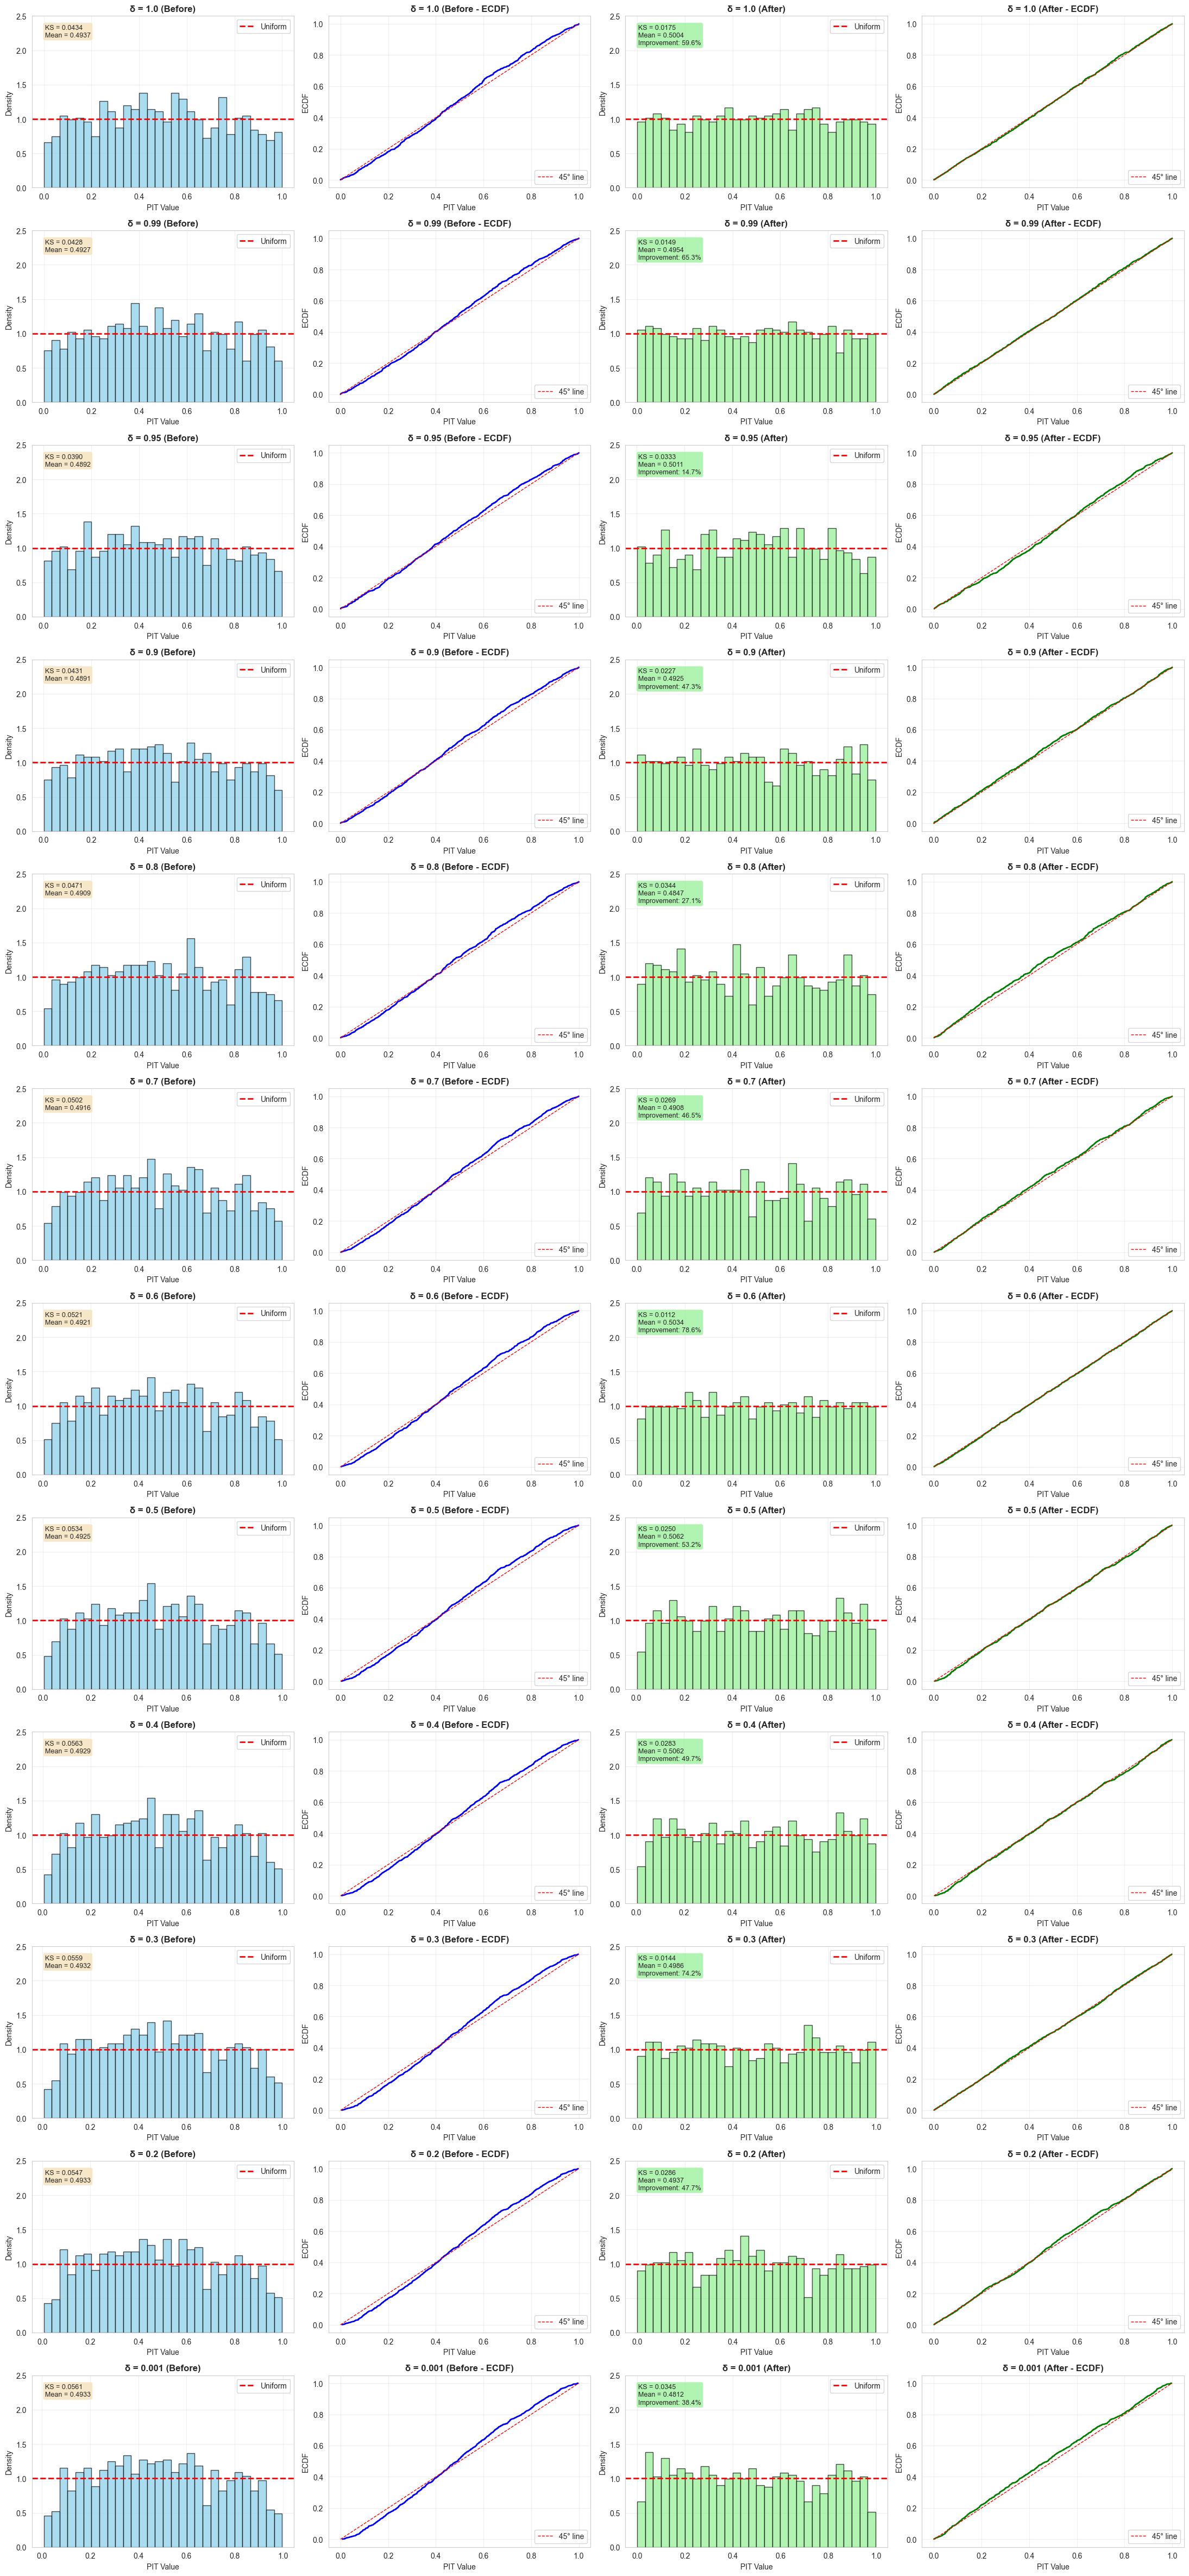

In [34]:
n_factors = len(discount_factors)
fig, axes = plt.subplots(n_factors, 4, figsize=(22, 4 * n_factors))

for i, result in enumerate(sim_results):
    delta = result['delta']
    u_original = result['u_original']
    v_transformed = result['v_transformed']
    
    # Before (left column)
    ax_before = axes[i, 0]
    ax_before.hist(u_original, bins=30, density=True, alpha=0.7, 
                   edgecolor='black', color='skyblue')
    ax_before.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Uniform')
    ax_before.set_title(f'δ = {delta} (Before)', fontsize=12, fontweight='bold')
    ax_before.set_xlabel('PIT Value', fontsize=10)
    ax_before.set_ylabel('Density', fontsize=10)
    ax_before.set_ylim([0, 2.5])
    ax_before.grid(True, alpha=0.3)
    ax_before.legend(loc='upper right')
    ax_before.text(0.05, 0.95, f'KS = {result["ks_before"]:.4f}\nMean = {result["mean_before"]:.4f}', 
                   transform=ax_before.transAxes, verticalalignment='top', fontsize=9,
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))
    
    # === Column 2: BEFORE ECDF ===
    ax_before_ecdf = axes[i, 1]
    plot_ecdf(ax_before_ecdf, u_original, f'δ = {delta} (Before - ECDF)', color='blue')
    
    # After (right column)
    ax_after = axes[i, 2]
    ax_after.hist(v_transformed, bins=30, density=True, alpha=0.7, 
                  edgecolor='black', color='lightgreen')
    ax_after.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Uniform')
    ax_after.set_title(f'δ = {delta} (After)', fontsize=12, fontweight='bold')
    ax_after.set_xlabel('PIT Value', fontsize=10)
    ax_after.set_ylabel('Density', fontsize=10)
    ax_after.set_ylim([0, 2.5])
    ax_after.grid(True, alpha=0.3)
    ax_after.legend(loc='upper right')
    
    # Calculate improvement
    improvement = ((result['ks_before'] - result['ks_after']) / result['ks_before'] * 100)
    improvement_color = 'green' if improvement > 0 else 'red'
    
    ax_after.text(0.05, 0.95, 
                  f'KS = {result["ks_after"]:.4f}\nMean = {result["mean_after"]:.4f}\nImprovement: {improvement:.1f}%', 
                  transform=ax_after.transAxes, verticalalignment='top', fontsize=9,
                  bbox=dict(boxstyle='round', facecolor='lightgreen' if improvement > 0 else 'lightcoral', alpha=0.7))
    
    # === Column 4: AFTER ECDF ===
    ax_after_ecdf = axes[i, 3]
    plot_ecdf(ax_after_ecdf, v_transformed, f'δ = {delta} (After - ECDF)', color='green')

plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.show()

### Calibrated PIT log likelihood: $\log p(v) = \log \frac{\pi (u)}{ |\det T_\theta(u)|}$ 

In [35]:
def calibrated_ll(
        log_original_pdf: np.ndarray,
        results: list,
        discount_factors: np.ndarray,
):
    calibrated_ll = np.zeros_like(log_original_pdf)
    for i in range(len(discount_factors)):
        absdet_i = results[i]['log_likelihood']
        calibrated_ll[i] = log_original_pdf[i,:] - absdet_i
    return calibrated_ll


calibrated_lls = calibrated_ll(log_before_pdf, sim_results, discount_factors)

### Log Likelihood Comparison

In [36]:
results_df = pd.DataFrame({
    'discount_factor': discount_factors,
    'Before Calibration': log_before_pdf.mean(axis=1),
    'After Calibration': calibrated_lls.mean(axis=1),})

results_df['Comparison'] = results_df['After Calibration'] > results_df['Before Calibration']
results_df['Comparison'] = results_df['Comparison'].map({True: 'Higher Log Score', False: 'Lower Log Score'})
results_df

,discount_factor,Before Calibration,After Calibration,Comparison
0,1.000,-0.466732,-0.506152,Lower Log Score
1,0.990,-0.455263,-0.483467,Lower Log Score
2,0.950,-0.425502,-0.429290,Lower Log Score
3,0.900,-0.418725,-0.422379,Lower Log Score
4,0.800,-0.416191,-0.428107,Lower Log Score
5,0.700,-0.416943,-0.434326,Lower Log Score
6,0.600,-0.419150,-0.460024,Lower Log Score
7,0.500,-0.421990,-0.447253,Lower Log Score
8,0.400,-0.425230,-0.446137,Lower Log Score
9,0.300,-0.428473,-0.476189,Lower Log Score


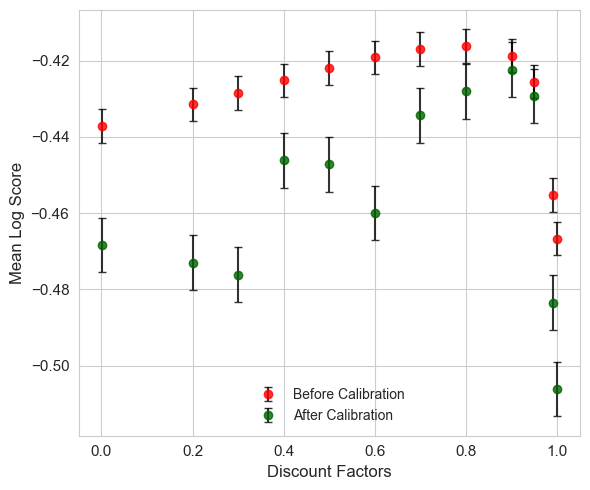

In [37]:
fig, ax = plt.subplots(1, 1, figsize=(6,5))

before_mean_log_score = results_df['Before Calibration']
after_mean_log_score = results_df['After Calibration']

# Example: assuming you have std errors (replace with your arrays)
before_std = np.std(before_mean_log_score) / np.sqrt(len(before_mean_log_score))
after_std = np.std(after_mean_log_score) / np.sqrt(len(after_mean_log_score))

ax.errorbar(discount_factors, before_mean_log_score, 
            yerr=before_std, fmt='o', 
            mfc='red', mec='red', ecolor='black', 
            label="Before Calibration", markersize=6, capsize=3, alpha=0.8)

ax.errorbar(discount_factors, after_mean_log_score, 
            yerr=after_std, fmt='o', 
            mfc='darkgreen', mec='darkgreen', ecolor='black', 
            label="After Calibration", markersize=6, capsize=3, alpha=0.8)
ax.set_ylabel("Mean Log Score", fontsize=12)
ax.set_xlabel("Discount Factors", fontsize=12)

ax.legend(loc="lower center", frameon=False, fontsize=10)
ax.tick_params(axis='both', labelsize=11)

fig.tight_layout()

### Time varying NSF

In [38]:
tv_sim_results = tvnsf_pit(
        K = 30,
        x = x_grid,
        y = sim_y,
        num_epochs=300,
        pit_data=Raw_pit,
        cdf_data=linear_pool,
        discount_factors=discount_factors[-2:],
        encoding_dim=64,
        hidden_size=32,
        seed=42
)

Running on device: cuda

Training for δ = 0.2
  Epoch    0 | Loss:   0.0241
  Epoch  200 | Loss:  -0.0237

Training for δ = 0.001
  Epoch    0 | Loss:   0.0399
  Epoch  200 | Loss:  -0.0088


In [39]:
tv_sim_before = np.zeros((len(discount_factors[-2:]),Raw_pit.shape[1]),dtype=float)
tv_sim_after = np.zeros((len(discount_factors[-2:]),Raw_pit.shape[1]),dtype=float)

for i in range(len(discount_factors[-2:])):
    tv_sim_before[i,:] = tv_sim_results[i]['u_original']
    tv_sim_after[i,:] = tv_sim_results[i]['v_transformed']

_, int_tv_df = test_and_interpret_pit(
    pit_values=tv_sim_before,
    discount_factors=discount_factors[-2:]
)

_, int_tv_df_1 = test_and_interpret_pit(
    pit_values=tv_sim_after,
    discount_factors=discount_factors[-2:]
)

In [40]:
int_tv_df

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 0.2,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
1,δ = 0.001,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL


In [41]:
int_tv_df_1

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 0.2,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS
1,δ = 0.001,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS


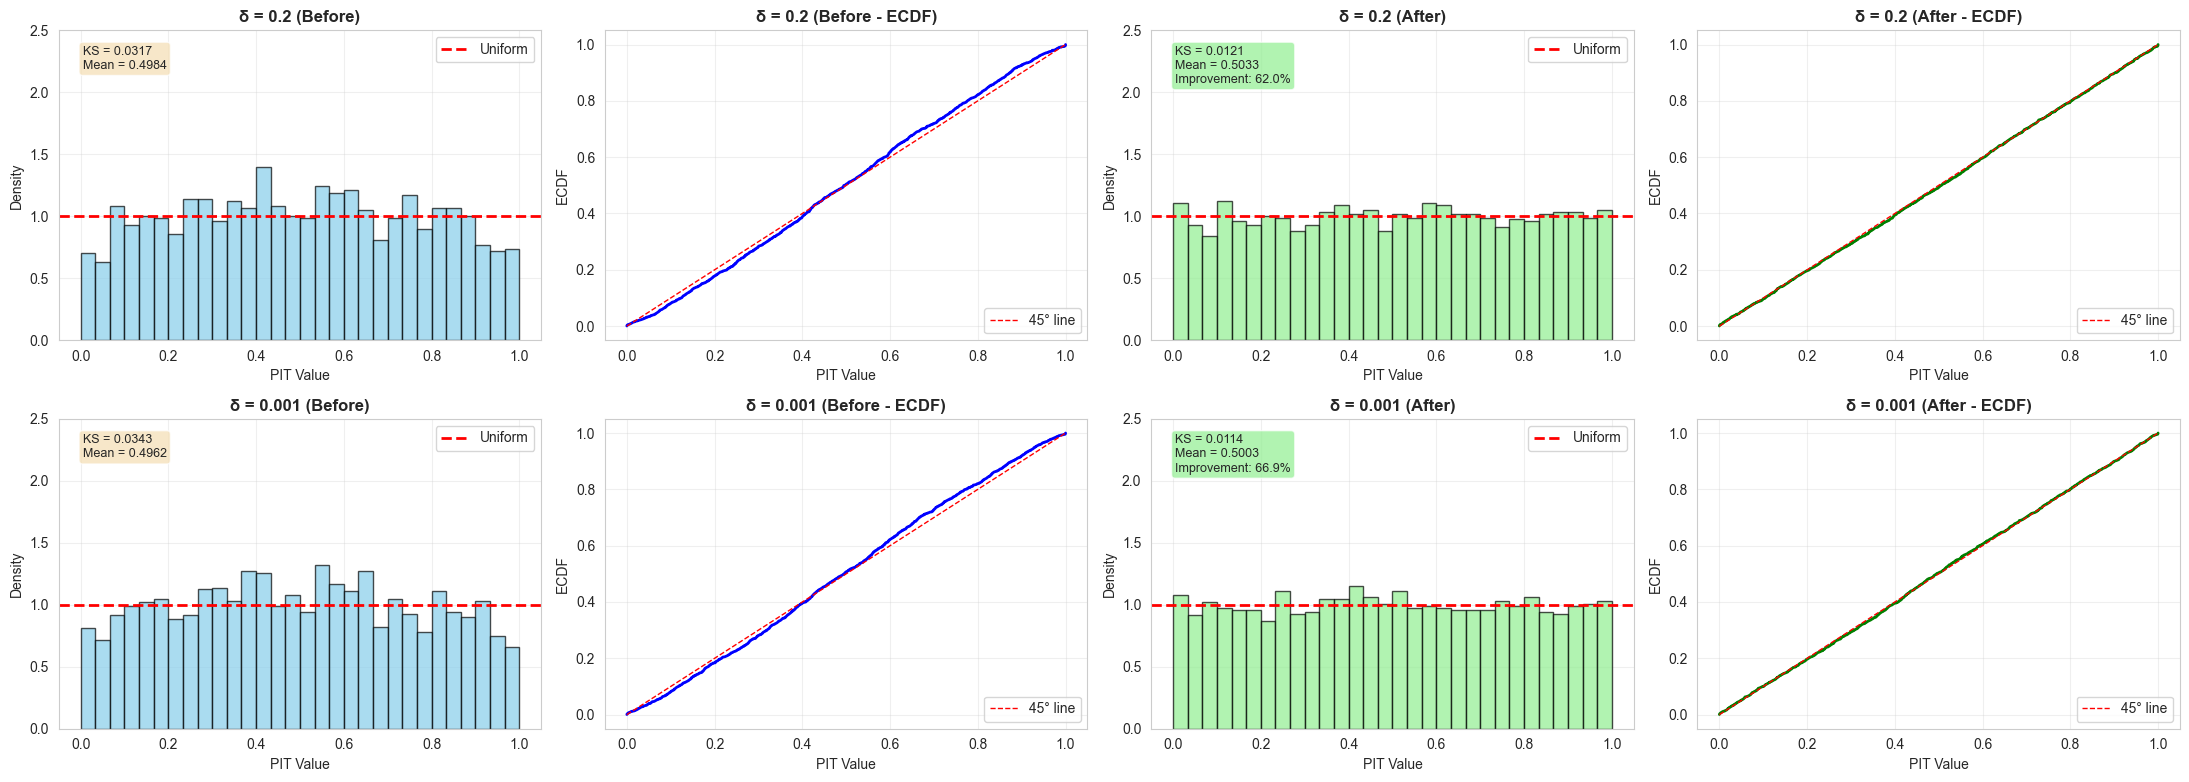

In [42]:
n_factors = len(discount_factors[-2:])
fig, axes = plt.subplots(n_factors, 4, figsize=(22, 4 * n_factors))

for i, result in enumerate(tv_sim_results):
    delta = result['delta']
    u_original = result['u_original']
    v_transformed = result['v_transformed']
    
    # Before (left column)
    ax_before = axes[i, 0]
    ax_before.hist(u_original, bins=30, density=True, alpha=0.7, 
                   edgecolor='black', color='skyblue')
    ax_before.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Uniform')
    ax_before.set_title(f'δ = {delta} (Before)', fontsize=12, fontweight='bold')
    ax_before.set_xlabel('PIT Value', fontsize=10)
    ax_before.set_ylabel('Density', fontsize=10)
    ax_before.set_ylim([0, 2.5])
    ax_before.grid(True, alpha=0.3)
    ax_before.legend(loc='upper right')
    ax_before.text(0.05, 0.95, f'KS = {result["ks_before"]:.4f}\nMean = {result["mean_before"]:.4f}', 
                   transform=ax_before.transAxes, verticalalignment='top', fontsize=9,
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))
    
    # === Column 2: BEFORE ECDF ===
    ax_before_ecdf = axes[i, 1]
    plot_ecdf(ax_before_ecdf, u_original, f'δ = {delta} (Before - ECDF)', color='blue')
    
    # After (right column)
    ax_after = axes[i, 2]
    ax_after.hist(v_transformed, bins=30, density=True, alpha=0.7, 
                  edgecolor='black', color='lightgreen')
    ax_after.axhline(1.0, color='red', linestyle='--', linewidth=2, label='Uniform')
    ax_after.set_title(f'δ = {delta} (After)', fontsize=12, fontweight='bold')
    ax_after.set_xlabel('PIT Value', fontsize=10)
    ax_after.set_ylabel('Density', fontsize=10)
    ax_after.set_ylim([0, 2.5])
    ax_after.grid(True, alpha=0.3)
    ax_after.legend(loc='upper right')
    
    # Calculate improvement
    improvement = ((result['ks_before'] - result['ks_after']) / result['ks_before'] * 100)
    improvement_color = 'green' if improvement > 0 else 'red'
    
    ax_after.text(0.05, 0.95, 
                  f'KS = {result["ks_after"]:.4f}\nMean = {result["mean_after"]:.4f}\nImprovement: {improvement:.1f}%', 
                  transform=ax_after.transAxes, verticalalignment='top', fontsize=9,
                  bbox=dict(boxstyle='round', facecolor='lightgreen' if improvement > 0 else 'lightcoral', alpha=0.7))
    
    # === Column 4: AFTER ECDF ===
    ax_after_ecdf = axes[i, 3]
    plot_ecdf(ax_after_ecdf, v_transformed, f'δ = {delta} (After - ECDF)', color='green')

plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.show()

### Log score comparison

In [43]:
tv_sim_log_before_pdf = np.log(TLP_pdf)[-2:]

tv_sim_log_after_pdf = calibrated_ll(tv_sim_log_before_pdf, tv_sim_results, discount_factors[-2:])


tv_sim_results_df = pd.DataFrame({
    'discount_factor': discount_factors[-2:],
    'Before Calibration': tv_sim_log_before_pdf.mean(axis=1),
    'After Calibration': tv_sim_log_after_pdf.mean(axis=1),})

tv_sim_results_df['Comparison'] = tv_sim_results_df['After Calibration'] > tv_sim_results_df['Before Calibration']
tv_sim_results_df['Comparison'] = tv_sim_results_df['Comparison'].map({True: 'Higher Log Score', False: 'Lower Log Score'})
tv_sim_results_df

,discount_factor,Before Calibration,After Calibration,Comparison
0,0.200,-0.412001,-0.451721,Lower Log Score
1,0.001,-0.417677,-0.448167,Lower Log Score


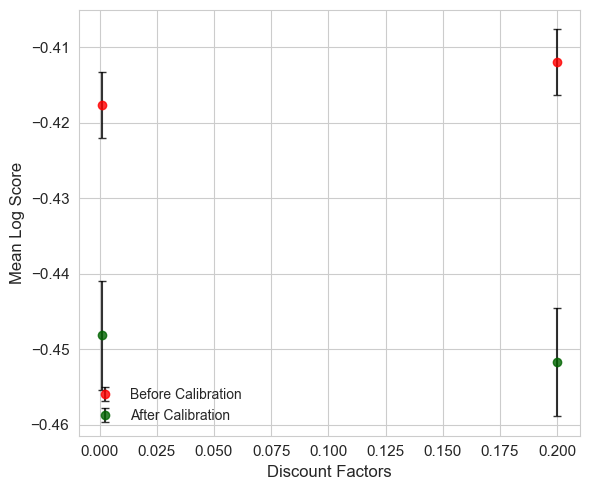

In [44]:
fig, ax = plt.subplots(1, 1, figsize=(6,5))

tv_sim_before_mean_log_score = tv_sim_results_df['Before Calibration']
tv_sim_after_mean_log_score = tv_sim_results_df['After Calibration']

# Example: assuming you have std errors (replace with your arrays)
before_std = np.std(before_mean_log_score) / np.sqrt(len(before_mean_log_score))
after_std = np.std(after_mean_log_score) / np.sqrt(len(after_mean_log_score))

ax.errorbar(discount_factors[-2:], tv_sim_before_mean_log_score, 
            yerr=before_std, fmt='o', 
            mfc='red', mec='red', ecolor='black', 
            label="Before Calibration", markersize=6, capsize=3, alpha=0.8)

ax.errorbar(discount_factors[-2:], tv_sim_after_mean_log_score, 
            yerr=after_std, fmt='o', 
            mfc='darkgreen', mec='darkgreen', ecolor='black', 
            label="After Calibration", markersize=6, capsize=3, alpha=0.8)
ax.set_ylabel("Mean Log Score", fontsize=12)
ax.set_xlabel("Discount Factors", fontsize=12)

ax.legend(loc="lower left", frameon=False, fontsize=10)
ax.tick_params(axis='both', labelsize=11)

fig.tight_layout()

In [45]:
beta_ece = []
nsf_ece = []

# Assuming discount_factors is the list used for both
for i in range(len(discount_factors)):
    # 1. Beta: Ensure this accesses the sequence of PITs for model i
    # (Assuming shape is [Models, TimeSteps])
    beta_pits = beta_transformed_pit['all_calibrated_cdfs'][i]
    beta_ece.append(compute_ece(beta_pits, n_bins=30))
    
    # 2. NSF: Use 'v_transformed' (the actual PIT values), NOT 'ece_score'
    nsf_pits = tv_sim_results[i]['v_transformed']
    nsf_ece.append(compute_ece(nsf_pits, n_bins=30))

# Convert to plotting
plt.figure(figsize=(10, 6))
plt.plot(discount_factors, beta_ece, label='Beta Calibration', marker='o')
plt.plot(discount_factors, nsf_ece, label='NSF Calibration', marker='x')

plt.xlabel('Discount Factor')
plt.ylabel('Expected Calibration Error (ECE)')
plt.title('ECE Comparison: Beta vs NSF (30 Bins)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

IndexError: list index out of range

In [46]:
tv_crps_result = tvnsf_pit_crps(
    K = 30,
    x = x_grid,
    y = sim_y,
    num_epochs=500,
    pit_data=Raw_pit,
    cdf_data=linear_pool,
    discount_factors=discount_factors[-1:],
    encoding_dim=64,
    hidden_size=64,
    seed=42
)

Running on device: cuda

Training for δ = 0.001
  Epoch    0 | Loss:   0.0343
  Epoch  200 | Loss:  -0.2868
  Epoch  400 | Loss:  -0.3613


In [47]:
tv_crps_before = np.zeros((len(discount_factors[-1:]),Raw_pit.shape[1]),dtype=float)
tv_crps_after = np.zeros((len(discount_factors[-1:]),Raw_pit.shape[1]),dtype=float)

for i in range(len(discount_factors[-1:])):
    tv_crps_before[i,:] = tv_crps_result[i]['u_original']
    tv_crps_after[i,:] = tv_crps_result[i]['v_transformed']

_, int_tv_crps_df = test_and_interpret_pit(
    pit_values=tv_crps_before,
    discount_factors=discount_factors[-1:]
)

_, int_tv_crps_df_1 = test_and_interpret_pit(
    pit_values=tv_crps_after,
    discount_factors=discount_factors[-1:]
)

In [48]:
int_tv_crps_df_1

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 0.001,0/9,FAIL,FAIL,FAIL,FAIL,FAIL,FAIL,FAIL,FAIL,FAIL


In [49]:
tv_crps_log_before_pdf = np.log(TLP_pdf)[-1:]

tv_crps_log_after_pdf = calibrated_ll(tv_crps_log_before_pdf, tv_crps_result, discount_factors[-1:])


tv_sim_results_df = pd.DataFrame({
    'discount_factor': discount_factors[-1:],
    'Before Calibration': tv_crps_log_before_pdf.mean(axis=1),
    'After Calibration': tv_crps_log_after_pdf.mean(axis=1),})

tv_sim_results_df['Comparison'] = tv_sim_results_df['After Calibration'] > tv_sim_results_df['Before Calibration']
tv_sim_results_df['Comparison'] = tv_sim_results_df['Comparison'].map({True: 'Higher Log Score', False: 'Lower Log Score'})
tv_sim_results_df

,discount_factor,Before Calibration,After Calibration,Comparison
0,0.001,-0.417677,-0.490542,Lower Log Score


In [133]:
from time_varying_nsf import online_beta_nsf_calibration

In [147]:
tlp_param = {
    'forecast': forecasts,
    'x': x_grid,
    'weights': res_ldf_2['weights'],
    'sigma_y': sigma_y
    }

two_stage = online_beta_nsf_calibration(
    K = 20,
    x=x_grid,
    y_observations=sim_y,
    pool_func=tlp,
    pool_param=tlp_param,
    geom_3f2=geom_3f2,
    num_epochs=200,
    discount_factors=discount_factors[-1:],
    encoding_dim=64,
    hidden_size=64,
    # Beta parameters (from your thesis)
    a0=1.0, b0=1.0,
    gamma=0.5, eta0=0.01, tau=50, alpha=0.85,
    seed=42
)

Stage 1: Online Beta Calibration
  Time steps (T): 2001
  Initial parameters: α₀=1.0, β₀=1.0
  Learning rate: η₀=0.01, τ=50, α=0.85
------------------------------------------------------------
  Step    0: α_mean=0.9998, β_mean=1.0001
  Step  200: α_mean=0.9992, β_mean=0.9987
  Step  400: α_mean=0.9991, β_mean=0.9986
  Step  600: α_mean=0.9991, β_mean=0.9986
  Step  800: α_mean=0.9991, β_mean=0.9985
  Step 1000: α_mean=0.9991, β_mean=0.9985
  Step 1200: α_mean=0.9990, β_mean=0.9985
  Step 1400: α_mean=0.9990, β_mean=0.9985
  Step 1600: α_mean=0.9990, β_mean=0.9985
  Step 1800: α_mean=0.9990, β_mean=0.9985
  Step 2000: α_mean=0.9990, β_mean=0.9985

STAGE 2: Neural Spline Flow Fine-Tuning

Training for δ = 0.001
  Epoch    0 | Loss:   0.0278


(array([0.91455658, 0.95953477, 0.92954921, 1.00451308, 1.12445494,
        0.929549  , 0.86957849, 1.1544404 , 0.94454215, 0.95953488,
        1.10946221, 0.95953402, 1.21441133, 1.01950581, 1.07947674,
        0.95953488, 1.01950581, 0.89956395, 1.21441133, 0.95953488,
        1.01950581, 1.07947674, 0.98951858, 0.97452761, 1.12445494,
        0.89956395, 0.94454215, 0.91455668, 0.91455668, 0.91455668]),
 array([7.62864283e-06, 3.33404578e-02, 6.66732863e-02, 1.00006118e-01,
        1.33338943e-01, 1.66671768e-01, 2.00004607e-01, 2.33337432e-01,
        2.66670257e-01, 3.00003082e-01, 3.33335906e-01, 3.66668731e-01,
        4.00001585e-01, 4.33334410e-01, 4.66667235e-01, 5.00000060e-01,
        5.33332884e-01, 5.66665709e-01, 5.99998534e-01, 6.33331358e-01,
        6.66664183e-01, 6.99997008e-01, 7.33329833e-01, 7.66662717e-01,
        7.99995542e-01, 8.33328366e-01, 8.66661191e-01, 8.99994016e-01,
        9.33326840e-01, 9.66659665e-01, 9.99992490e-01]),
 <BarContainer object of 30 

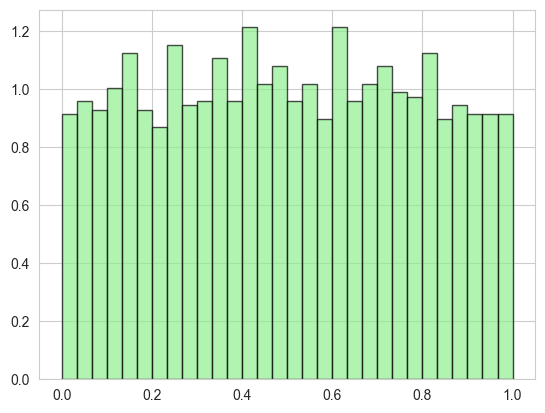

In [148]:
plt.hist(two_stage[0]['pit_final'],bins=30, density=True, alpha=0.7, 
         edgecolor='black', color='lightgreen')

In [149]:
tv_crps_before = np.zeros((len(discount_factors[-1:]),Raw_pit.shape[1]),dtype=float)
after = np.zeros((len(discount_factors[-1:]),Raw_pit.shape[1]),dtype=float)

for i in range(len(discount_factors[-1:])):
    tv_crps_before[i,:] = tv_crps_result[i]['u_original']
    after[i,:] = two_stage[i]['pit_final']

_, int_tv_crps_df = test_and_interpret_pit(
    pit_values=tv_crps_before,
    discount_factors=discount_factors[-1:]
)

_, int_1 = test_and_interpret_pit(
    pit_values=after,
    discount_factors=discount_factors[-1:]
)

In [150]:
int_1

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 0.001,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS


In [151]:
tv_crps_log_before_pdf = np.log(TLP_pdf)[-1:]

tv_crps_log_after_pdf = calibrated_ll(tv_crps_log_before_pdf, two_stage, discount_factors[-1:])


tv_sim_results_df = pd.DataFrame({
    'discount_factor': discount_factors[-1:],
    'Before Calibration': tv_crps_log_before_pdf.mean(axis=1),
    'After Calibration': tv_crps_log_after_pdf.mean(axis=1),})

tv_sim_results_df['Comparison'] = tv_sim_results_df['After Calibration'] > tv_sim_results_df['Before Calibration']
tv_sim_results_df['Comparison'] = tv_sim_results_df['Comparison'].map({True: 'Higher Log Score', False: 'Lower Log Score'})
tv_sim_results_df

,discount_factor,Before Calibration,After Calibration,Comparison
0,0.001,-0.417677,-0.441048,Lower Log Score


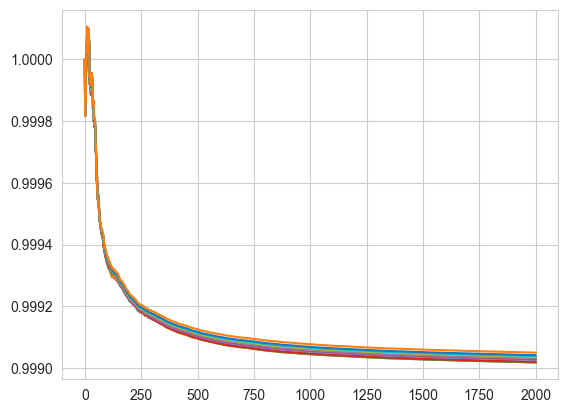

In [154]:
plt.plot(np.arange(2002),np.array(two_stage[0]['a_hist']))

In [168]:
from time_varying_nsf import nsf_direct_crps_calibration

ImportError: cannot import name 'nsf_direct_crps_calibration' from 'time_varying_nsf' (c:\Users\callu\OneDrive\Desktop\nsf_pit\time_varying_nsf.py)